## Centered Rolling Mean

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.api import SimpleExpSmoothing, Holt, ExponentialSmoothing

In [2]:
df = pd.read_csv("../Datasets/monthly-milk-production-pounds-p.csv")
df

,Month,Milk
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727
...,...,...
163,1975-08,858
164,1975-09,817
165,1975-10,827
166,1975-11,797


In [3]:
y = df["Milk"]

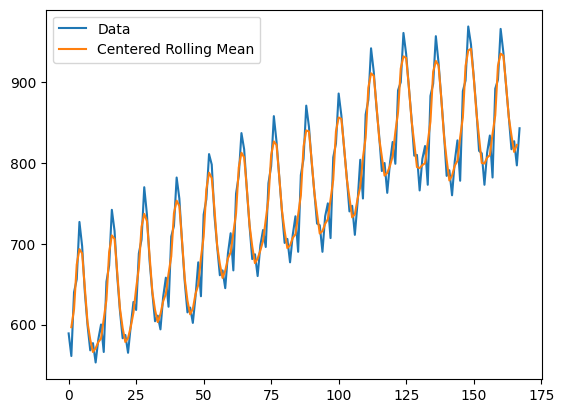

In [4]:
span = 3
fcast = y.rolling(span, center=True).mean()
plt.plot(y, label="Data")
plt.plot(fcast, label="Centered Rolling Mean")  # Fixed: changed df to fcast
plt.legend(loc="best")
plt.show()

# Trailing Rolling Mean

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

In [6]:
y_train, y_test = df["Milk"][:-12], df["Milk"][-12:]
y_train.shape, y_test.shape

((156,), (12,))

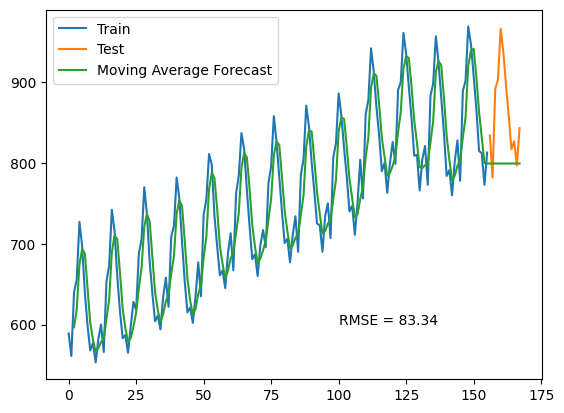

In [7]:
span = 3
fcast = y_train.rolling(span).mean()
MA = fcast.iloc[-1]
MA_series = pd.Series(MA.repeat(len(y_test)))
MA_fcast = pd.concat([fcast, MA_series], ignore_index=True)
plt.plot(y_train , label = 'Train')
plt.plot(y_test , label = 'Test')
plt.plot(MA_fcast , label='Moving Average Forecast')
rms = np.round(root_mean_squared_error(y_test , MA_series) , 2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()

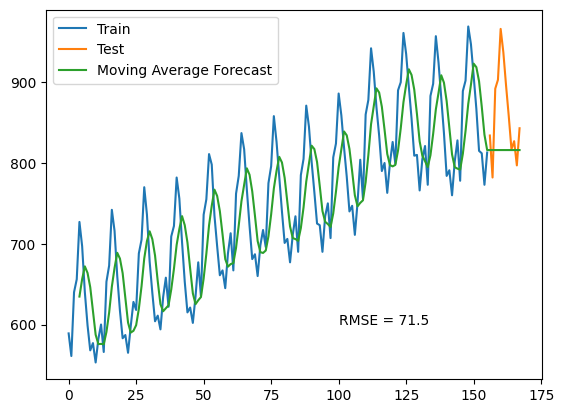

In [8]:
span = 5
fcast = y_train.rolling(span).mean()
MA = fcast.iloc[-1]
MA_series = pd.Series(MA.repeat(len(y_test)))
MA_fcast = pd.concat([fcast, MA_series], ignore_index=True)
plt.plot(y_train , label = 'Train')
plt.plot(y_test , label = 'Test')
plt.plot(MA_fcast , label='Moving Average Forecast')
rms = np.round(root_mean_squared_error(y_test , MA_series) , 2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()

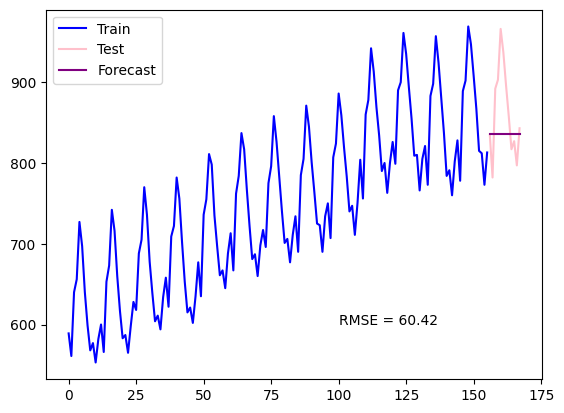

In [9]:
alpha = 0.2
ses = SimpleExpSmoothing(y_train, initialization_method="estimated")
fit1 = ses.fit(smoothing_level=alpha)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color='b', label="Train")
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label="Forecast")
res = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(100, 600, f'RMSE = {res}')
plt.legend(loc='best')
plt.show()

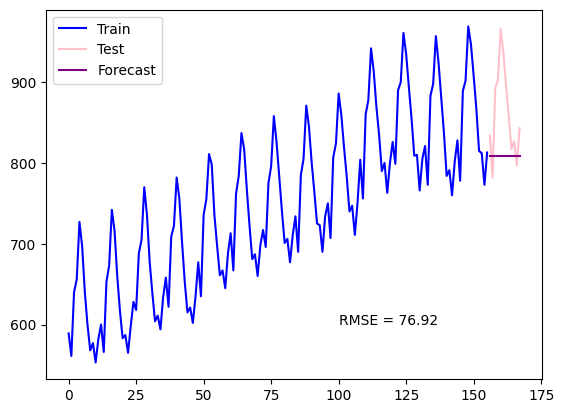

In [10]:
alpha = 0.5
ses = SimpleExpSmoothing(y_train, initialization_method="estimated")
fit1 = ses.fit(smoothing_level=alpha)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color='b', label="Train")
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label="Forecast")
res = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(100, 600, f'RMSE = {res}')
plt.legend(loc='best')
plt.show()

## Holt's Linear Trend Method

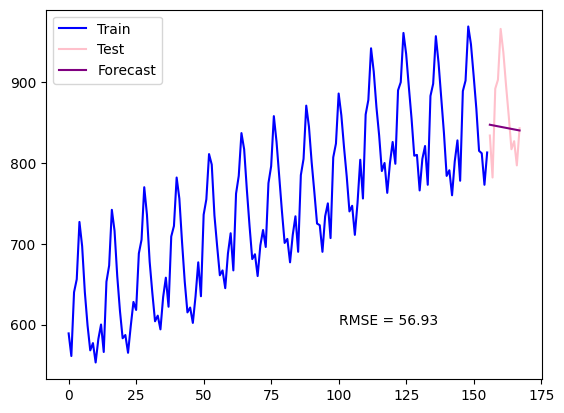

In [11]:
alpha, beta = 0.1, 0.2
holt = Holt(y_train, initialization_method="estimated")
fit1 = holt.fit(smoothing_level=alpha, smoothing_trend=beta)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color='b', label="Train")
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label="Forecast")
res = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(100, 600, f'RMSE = {res}')
plt.legend(loc='best')
plt.show()

# Exponetial Smoothing

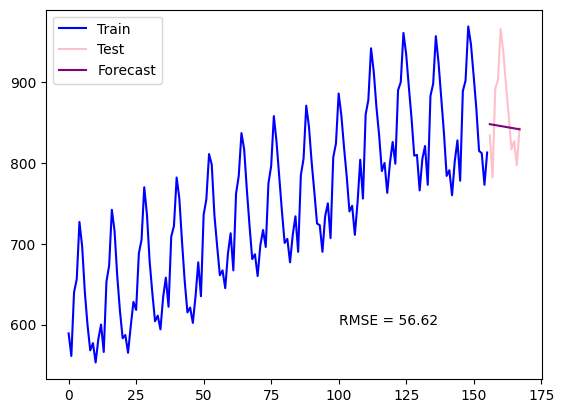

In [12]:
alpha, beta = 0.1, 0.2
holt = Holt(y_train, exponential=True, initialization_method="estimated")
fit1 = holt.fit(smoothing_level=alpha, smoothing_trend=beta)
fcast1 = fit1.forecast(len(y_test))

y_train.plot(color='b', label="Train")
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label="Forecast")
res = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(100, 600, f'RMSE = {res}')
plt.legend(loc='best')
plt.show()

# Damped Trend Method

## Additive Damped Trend

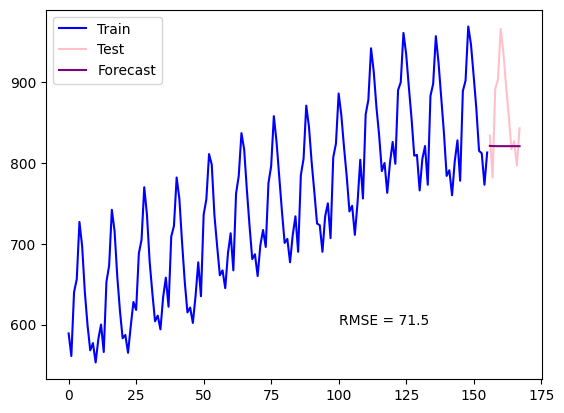

In [13]:
alpha, beta, phi = 0.3, 0.2, 0.3
holt = Holt(y_train, damped_trend = True,initialization_method="estimated")
fit1 = holt.fit(smoothing_level=alpha, 
                smoothing_trend = beta,
               damping_trend = phi, optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label="Train")
y_test.plot(color='pink', label = 'Test')
fcast1.plot(color = 'purple', label = "Forecast")
res = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()

## Additive Exponential

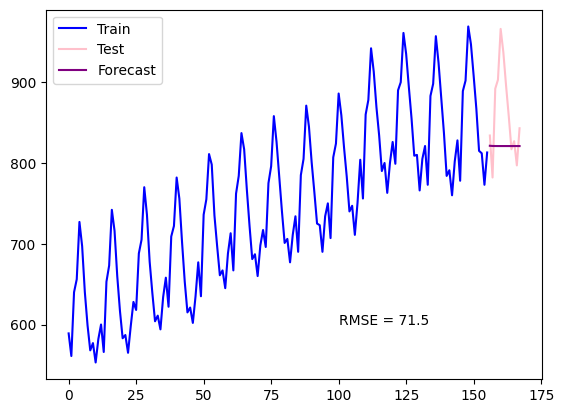

In [14]:
alpha, beta, phi = 0.3, 0.2, 0.3
holt = Holt(y_train, damped_trend = True,exponential=True,initialization_method="estimated")
fit1 = holt.fit(smoothing_level=alpha, 
                smoothing_trend = beta,
               damping_trend = phi, optimized=False)
fcast1 = fit1.forecast(len(y_test))
y_train.plot(color = 'blue', label="Train")
y_test.plot(color='pink', label = 'Test')
fcast1.plot(color = 'purple', label = "Forecast")
res = np.round(root_mean_squared_error(y_test, fcast1),2)
plt.text(100,600, f'RMSE = {rms}')
plt.legend(loc= 'best')
plt.show()

## Holt=Winter Additive

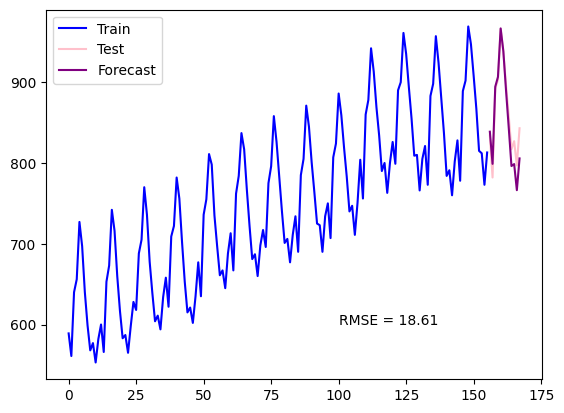

In [15]:
alpha, beta, gamma = 0.6, 0.2, 0.1 
hw_add = ExponentialSmoothing(
    y_train, 
    seasonal_periods=12, 
    trend='add', 
    seasonal='add', 
    initialization_method="estimated"
)

# FIXED: call fit on hw_add instead of holt, and fix argument passing
fit1 = hw_add.fit(
    smoothing_level=alpha, 
    smoothing_trend=beta, 
    smoothing_seasonal=gamma
)

fcast1 = fit1.forecast(len(y_test))

y_train.plot(color='blue', label="Train")
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label="Forecast")

res = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(100, 600, f'RMSE = {res}')
plt.legend(loc='best')
plt.show()

## Automatic Optimization

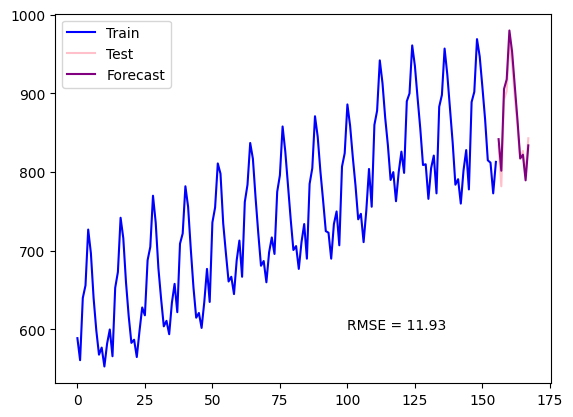

In [16]:
hw_add_auto = ExponentialSmoothing(
    y_train, 
    seasonal_periods=12, 
    trend='add', 
    seasonal='add', 
    initialization_method="estimated"
)

# Automatically estimate/optimize the smoothing levels
fit1 = hw_add_auto.fit(optimized = True)

fcast1 = fit1.forecast(len(y_test))

y_train.plot(color='blue', label="Train")
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label="Forecast")

res = np.round(root_mean_squared_error(y_test, fcast1), 2)
plt.text(100, 600, f'RMSE = {res}')
plt.legend(loc='best')
plt.show()

In [17]:
alpha , beta = np.linspace(0.01,0.99,10), np.linspace(0.01,0.99,10)
gamma = np.linspace(0.01,0.99,10)
scores =[]
for a in tqdm(alpha):
    for b in beata:
        for g in gamma:
            hw_add - 

SyntaxError: invalid syntax (1214600301.py, line 7)